In [1]:
# =========================================
# IMPORTS
# =========================================
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# =========================================
# PATHS
# =========================================
base_path = r"C:\Users\ramya\OneDrive\Desktop\China_projects\Nursing_multimodal_proejct"
clinical_path = os.path.join(base_path, "mimic3d_labeled.csv")
image_path = os.path.join(base_path, "image_aligned.csv")

# =========================================
# LOAD DATA
# =========================================
clinical_df = pd.read_csv(clinical_path)
image_df = pd.read_csv(image_path)

# =========================================
# SPLIT FIRST (NO LEAKAGE)
# =========================================
clinical_train, clinical_test = train_test_split(
    clinical_df, test_size=0.2,
    stratify=clinical_df['risk_label'],
    random_state=42
)

image_train, image_test = train_test_split(
    image_df, test_size=0.2,
    stratify=image_df['risk_label'],
    random_state=42
)

# ALIGN AFTER SPLIT
train_len = min(len(clinical_train), len(image_train))
test_len = min(len(clinical_test), len(image_test))

clinical_train = clinical_train.iloc[:train_len].reset_index(drop=True)
image_train = image_train.iloc[:train_len].reset_index(drop=True)

clinical_test = clinical_test.iloc[:test_len].reset_index(drop=True)
image_test = image_test.iloc[:test_len].reset_index(drop=True)

y_train = clinical_train['risk_label'].values
y_test = clinical_test['risk_label'].values

# =========================================
# CLINICAL FEATURES
# =========================================
Xc_train = clinical_train.drop(columns=['risk_label']).select_dtypes(include=[np.number])
Xc_test = clinical_test.drop(columns=['risk_label']).select_dtypes(include=[np.number])

scaler = StandardScaler()
Xc_train = scaler.fit_transform(Xc_train)
Xc_test = scaler.transform(Xc_test)

# =========================================
# IMAGE AUGMENTATION
# =========================================
IMG_SIZE = 224

datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

def load_images(paths, augment=False):
    imgs = []
    for p in paths:
        try:
            img = load_img(p, target_size=(IMG_SIZE, IMG_SIZE))
            img = img_to_array(img)
            if augment:
                img = datagen.random_transform(img)
            img = img / 255.0
            imgs.append(img)
        except:
            imgs.append(np.zeros((IMG_SIZE, IMG_SIZE, 3)))
    return np.array(imgs)

Xi_train = load_images(image_train['image_path'], True)
Xi_test = load_images(image_test['image_path'], False)

# =========================================
# CLASS WEIGHTS
# =========================================
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(class_weights))

# =========================================
# IMAGE MODEL (EfficientNet)
# =========================================
image_input = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=image_input)

# Freeze most layers
for layer in base_model.layers[:-40]:
    layer.trainable = False

feature_map = base_model.output
tokens = Reshape((-1, feature_map.shape[-1]))(feature_map)
image_tokens = Dense(256)(tokens)

# =========================================
# CLINICAL MODEL
# =========================================
clinical_input = Input(shape=(Xc_train.shape[1],))

c = Dense(128, activation='relu')(clinical_input)
c = BatchNormalization()(c)
c = Dropout(0.3)(c)
c = Dense(256, activation='relu')(c)

clinical_tokens = RepeatVector(tokens.shape[1])(c)

# =========================================
# TRANSFORMER FUSION (LIGHT VERSION)
# =========================================
attention = MultiHeadAttention(num_heads=2, key_dim=32)

attn_output = attention(
    query=clinical_tokens,
    key=image_tokens,
    value=image_tokens
)

# Residual connection
x = Add()([clinical_tokens, attn_output])
x = LayerNormalization()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)

x = GlobalAveragePooling1D()(x)

# =========================================
# CLASSIFIER
# =========================================
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

output = Dense(3, activation='softmax')(x)

# =========================================
# MODEL
# =========================================
model = Model(inputs=[image_input, clinical_input], outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,603,750 (17.56 MB)

 Trainable params: 2,604,627 (9.94 MB)

 Non-trainable params: 1,999,123 (7.63 MB)

In [2]:
# =========================================
# TRAIN (PHASE 1)
# =========================================
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
lr_sched = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3)

model.fit(
    [Xi_train, Xc_train],
    y_train,
    validation_data=([Xi_test, Xc_test], y_test),
    epochs=12,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop, lr_sched]
)

# =========================================
# FINE-TUNING (PHASE 2)
# =========================================
for layer in base_model.layers[-30:]:
    layer.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    [Xi_train, Xc_train],
    y_train,
    validation_data=([Xi_test, Xc_test], y_test),
    epochs=8,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop, lr_sched]
)


Epoch 1/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 141s 798ms/step - accuracy: 0.4529 - loss: 0.9936 - val_accuracy: 0.6748 - val_loss: 0.6801 - learning_rate: 3.0000e-04
Epoch 2/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.6531 - loss: 0.6838 - val_accuracy: 0.7832 - val_loss: 0.5014 - learning_rate: 3.0000e-04
Epoch 3/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 143s 923ms/step - accuracy: 0.7286 - loss: 0.5921 - val_accuracy: 0.7961 - val_loss: 0.4724 - learning_rate: 3.0000e-04
Epoch 4/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 120s 775ms/step - accuracy: 0.7324 - loss: 0.5827 - val_accuracy: 0.8560 - val_loss: 0.3723 - learning_rate: 3.0000e-04
Epoch 5/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 124s 803ms/step - accuracy: 0.7974 - loss: 0.4565 - val_accuracy: 0.8754 - val_loss: 0.3114 - learning_rate: 3.0000e-04
Epoch 6/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 121s 783ms/step - accuracy: 0.7801 - loss: 0.4894 - val_accuracy: 0.8641 - val_loss: 0.3079 - learning_rate: 3.0000e-04
Epoch 7/12
155/155 ━━━━━━━━━━━━━━━━━━━━ 138

In [3]:
# =========================================
# EVALUATION
# =========================================
loss, acc = model.evaluate([Xi_test, Xc_test], y_test)
print("\nFinal Test Accuracy:", acc)

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 544ms/step - accuracy: 0.9369 - loss: 0.1581

Final Test Accuracy: 0.9255663156509399


In [4]:
from sklearn.metrics import *

# Predictions
y_pred_prob = model.predict([Xi_test, Xc_test])
y_pred = np.argmax(y_pred_prob, axis=1)

20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 813ms/step


In [5]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

           0       0.94      0.97      0.96       153
           1       0.95      0.87      0.91       264
           2       0.89      0.96      0.92       201

    accuracy                           0.93       618
   macro avg       0.93      0.94      0.93       618
weighted avg       0.93      0.93      0.93       618



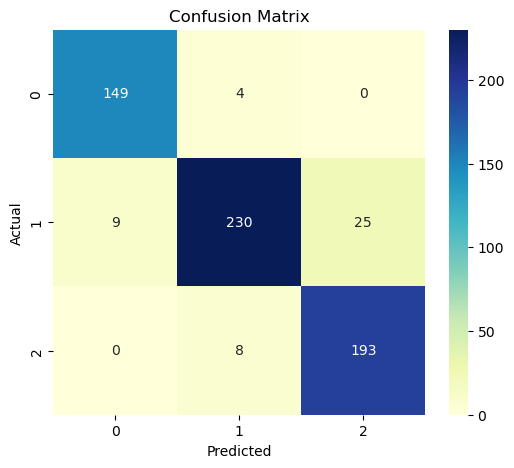

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("confusion_matrix.png",dpi=1000)
plt.show()

In [7]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

Accuracy  : 0.9256
Precision : 0.9274
Recall    : 0.9256
F1-score  : 0.9252


In [8]:
# Per-class sensitivity & specificity
for i in range(len(cm)):
    TP = cm[i, i]
    FN = np.sum(cm[i, :]) - TP
    FP = np.sum(cm[:, i]) - TP
    TN = np.sum(cm) - (TP + FP + FN)

    sensitivity = TP / (TP + FN + 1e-8)
    specificity = TN / (TN + FP + 1e-8)

    print(f"\nClass {i}:")
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity        : {specificity:.4f}")


Class 0:
Sensitivity (Recall): 0.9739
Specificity        : 0.9806

Class 1:
Sensitivity (Recall): 0.8712
Specificity        : 0.9661

Class 2:
Sensitivity (Recall): 0.9602
Specificity        : 0.9400


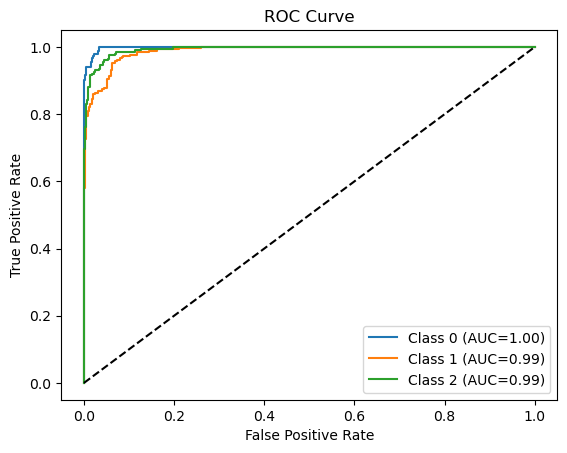

In [12]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_test_bin = label_binarize(y_test, classes=[0,1,2])

plt.figure()

for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'Class {i} (AUC={roc_auc:.2f})')

plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.savefig("ROC_Curve.png",dpi=1200)
plt.show()

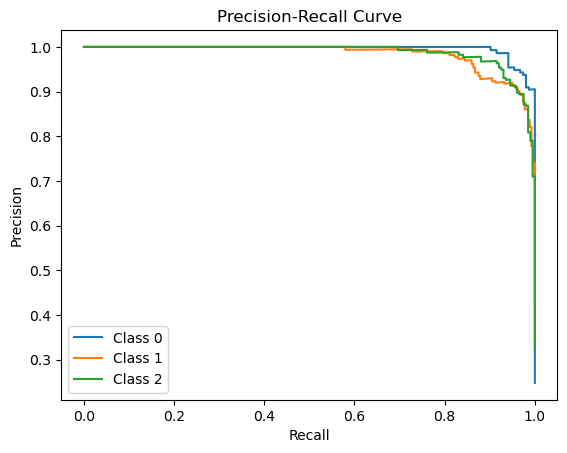

In [13]:
from sklearn.metrics import precision_recall_curve

plt.figure()

for i in range(3):
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_pred_prob[:, i]
    )

    plt.plot(recall_curve, precision_curve, label=f'Class {i}')

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.savefig("PR-Curve.png",dpi=1200)
plt.show()

In [14]:
kappa = cohen_kappa_score(y_test, y_pred)
print("Cohen Kappa:", round(kappa,4))

Cohen Kappa: 0.8863


In [15]:
mcc = matthews_corrcoef(y_test, y_pred)
print("MCC:", round(mcc,4))

MCC: 0.8877


In [16]:
balanced_acc = balanced_accuracy_score(y_test, y_pred)
print("Balanced Accuracy:", round(balanced_acc,4))

Balanced Accuracy: 0.9351


In [17]:
def grad_cam(model, img, clinical):

    # 🔥 correct last conv layer
    last_conv_layer = model.get_layer("top_conv")

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[last_conv_layer.output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_output, preds = grad_model([img, clinical])
        class_idx = tf.argmax(preds[0])
        loss = preds[:, class_idx]

    # Compute gradients
    grads = tape.gradient(loss, conv_output)

    # Global average pooling
    weights = tf.reduce_mean(grads, axis=(0,1,2))

    # Weighted sum
    cam = tf.reduce_sum(weights * conv_output[0], axis=-1)

    # ReLU
    cam = tf.maximum(cam, 0)

    # Normalize
    cam = cam / (tf.reduce_max(cam) + 1e-8)

    # Convert to numpy
    cam = cam.numpy()

    # Resize safely
    cam = cv2.resize(cam.astype(np.float32), (224,224))

    return cam

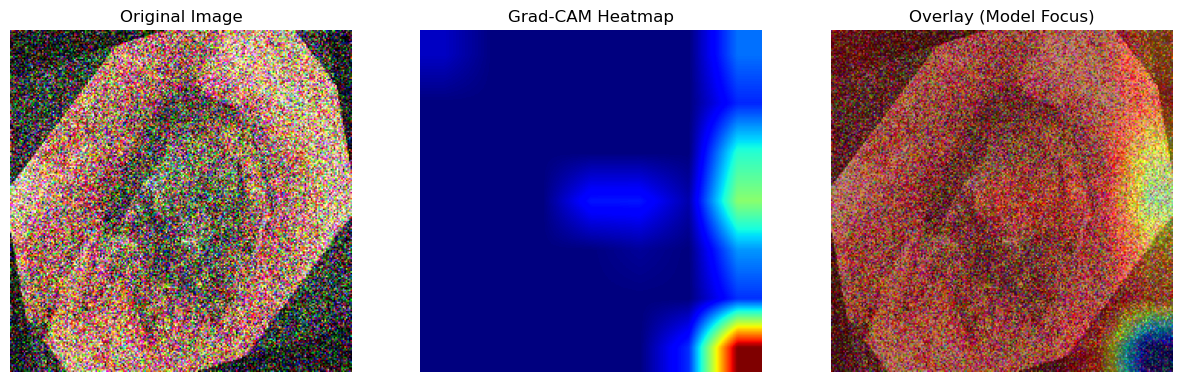

In [18]:
# =========================================
# VISUALIZATION (GRAD-CAM OVERLAY)
# =========================================

sample_img = Xi_test[0:1]
sample_clinical = Xc_test[0:1]

heatmap = grad_cam(model, sample_img, sample_clinical)

# Normalize heatmap
heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min())

# Convert to color
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)

# Resize original image
original_img = sample_img[0]
original_img = (original_img * 255).astype(np.uint8)

# Overlay heatmap
overlay = cv2.addWeighted(original_img, 0.6, heatmap_color, 0.4, 0)

# =========================================
# DISPLAY
# =========================================
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(original_img)
plt.title("Original Image")
plt.savefig("original_Image.png",dpi=1200)
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM Heatmap")
plt.savefig("Grad-CAM Heatmap.png",dpi=1200)
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title("Overlay (Model Focus)")
plt.savefig("Overlay.png",dpi=1200)
plt.axis('off')

plt.show()

20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 974ms/step
Baseline Accuracy: 0.9255663430420712
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 1000ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 896ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 883ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 890ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 973ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 918ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 871ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 949ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 929ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 961ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 975ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 976ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 966ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 953ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 928ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 972ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 935ms/step


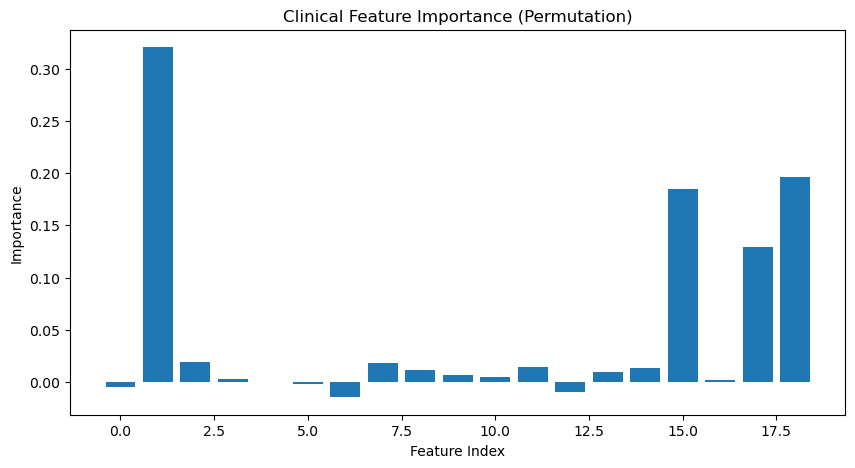

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================
# BASELINE PERFORMANCE
# =========================================
def get_accuracy(Xc, Xi, y):
    preds = model.predict([Xi, Xc])
    preds = np.argmax(preds, axis=1)
    return np.mean(preds == y)

baseline_acc = get_accuracy(Xc_test, Xi_test, y_test)
print("Baseline Accuracy:", baseline_acc)

# =========================================
# PERMUTATION IMPORTANCE
# =========================================
feature_importance = []

for i in range(Xc_test.shape[1]):
    
    Xc_permuted = Xc_test.copy()
    
    # shuffle one feature
    np.random.shuffle(Xc_permuted[:, i])
    
    acc = get_accuracy(Xc_permuted, Xi_test, y_test)
    
    importance = baseline_acc - acc
    feature_importance.append(importance)

feature_importance = np.array(feature_importance)

# =========================================
# VISUALIZATION
# =========================================
plt.figure(figsize=(10,5))
plt.bar(range(len(feature_importance)), feature_importance)
plt.title("Clinical Feature Importance (Permutation)")
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.savefig("feature_importance.png",dpi=1200)
plt.show()

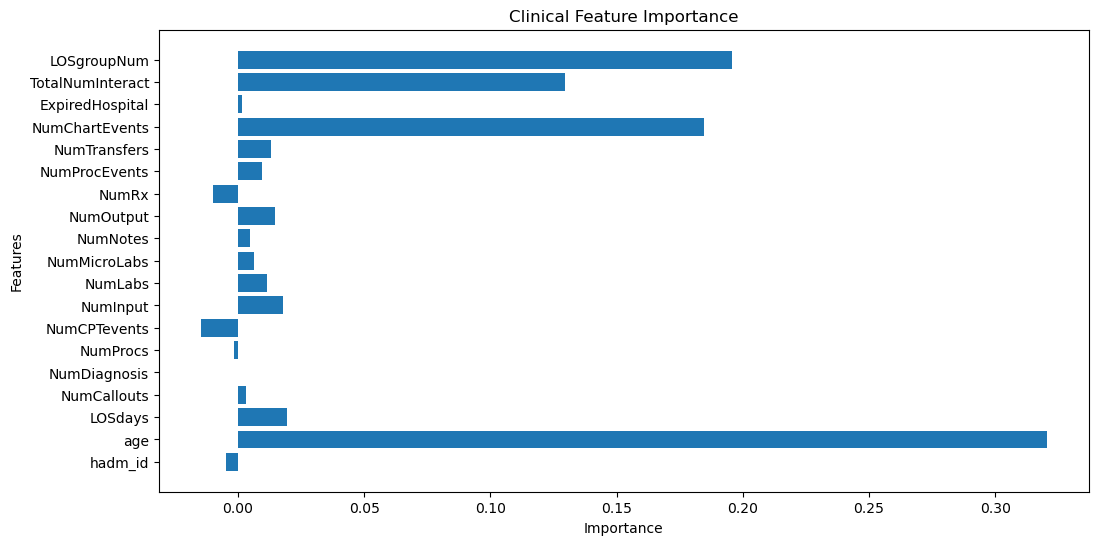

In [20]:
feature_names = clinical_df.drop(columns=['risk_label']).select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12,6))
plt.barh(feature_names, feature_importance)
plt.title("Clinical Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.savefig("features.png",dpi=1200)
plt.show()

In [21]:
# =========================================
# TRANSFORMER FUSION (WITH ATTENTION SCORES)
# =========================================
attention_layer = MultiHeadAttention(
    num_heads=2,
    key_dim=32,
    name="cross_attention"
)

attn_output, attn_scores = attention_layer(
    query=clinical_tokens,
    key=image_tokens,
    value=image_tokens,
    return_attention_scores=True
)

x = Add()([clinical_tokens, attn_output])
x = LayerNormalization()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)

x = GlobalAveragePooling1D()(x)

In [22]:
# =========================================
# ATTENTION MODEL (FOR XAI)
# =========================================
attention_model = Model(
    inputs=model.inputs,
    outputs=attn_scores
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step


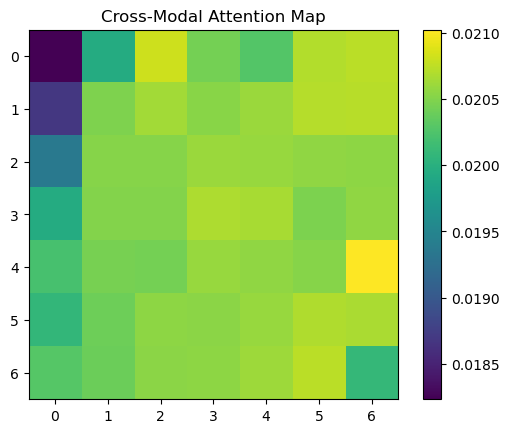

In [27]:
# =========================================
# ATTENTION VISUALIZATION
# =========================================
attn_scores = attention_model.predict([sample_img, sample_clinical])

# Remove batch dimension
attn_scores = attn_scores[0]

# Average over heads
attn_scores = attn_scores.mean(axis=0)

# Reduce to spatial map
attn_map = attn_scores.mean(axis=0)

# Reshape to square
size = int(np.sqrt(len(attn_map)))
attn_map = attn_map.reshape(size, size)

# Plot
plt.imshow(attn_map, cmap='viridis')
plt.title("Cross-Modal Attention Map")
plt.savefig("cross-modal_attension.png",dpi=1200)
plt.colorbar()
plt.show()

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score

# Image Only model

In [28]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
import tensorflow as tf

def build_image_only():
    image_input = Input(shape=(224,224,3))

    base = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=image_input)

    x = GlobalAveragePooling2D()(base.output)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.3)(x)
    output = Dense(3, activation='softmax')(x)

    model = Model(image_input, output)

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Clinical only Model

In [30]:
def build_clinical_only(input_dim):
    clinical_input = Input(shape=(input_dim,))

    x = Dense(128, activation='relu')(clinical_input)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(64, activation='relu')(x)

    output = Dense(3, activation='softmax')(x)

    model = Model(clinical_input, output)

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Concat Fusion without Transformer

In [31]:
def build_concat_model(input_dim):
    image_input = Input(shape=(224,224,3))
    clinical_input = Input(shape=(input_dim,))

    base = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=image_input)
    img_feat = GlobalAveragePooling2D()(base.output)

    clin_feat = Dense(128, activation='relu')(clinical_input)

    merged = Concatenate()([img_feat, clin_feat])

    x = Dense(128, activation='relu')(merged)
    x = Dropout(0.3)(x)

    output = Dense(3, activation='softmax')(x)

    model = Model([image_input, clinical_input], output)

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# TRAIN & EVALUATE ALL MODELS

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model_full(model, Xi_test, Xc_test, y_test):
    
    y_pred_prob = model.predict([Xi_test, Xc_test])
    y_pred = np.argmax(y_pred_prob, axis=1)

    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    return acc, precision, recall, f1

In [33]:
results = []

# ==========================
# IMAGE ONLY
# ==========================
img_model = build_image_only()
img_model.fit(Xi_train, y_train, epochs=5, batch_size=16, verbose=0)



NameError: name 'evaluate_model' is not defined

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model_full(model, Xi_test, Xc_test, y_test, model_type):
    
    # ==========================
    # PREDICTION
    # ==========================
    if model_type == "image":
        y_pred_prob = model.predict(Xi_test)

    elif model_type == "clinical":
        y_pred_prob = model.predict(Xc_test)

    elif model_type == "multimodal":
        y_pred_prob = model.predict([Xi_test, Xc_test])

    else:
        raise ValueError("Invalid model type")

    y_pred = np.argmax(y_pred_prob, axis=1)

    # ==========================
    # METRICS
    # ==========================
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    return acc, precision, recall, f1

In [36]:

acc, prec, rec, f1 = evaluate_model_full(
    img_model,
    Xi_test,
    Xc_test,
    y_test,
    model_type="image"
)

results.append(["Image Only", acc, prec, rec, f1])

20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 778ms/step


In [37]:
# ==========================
# CLINICAL ONLY
# ==========================
clin_model = build_clinical_only(Xc_train.shape[1])
clin_model.fit(Xc_train, y_train, epochs=5, batch_size=16, verbose=0)



In [38]:
y_pred = np.argmax(clin_model.predict(Xc_test), axis=1)
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

# Store results (FULL METRICS)
results.append(["Clinical Only", acc, precision, recall, f1])


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [40]:
acc, prec, rec, f1 = evaluate_model_full(
    concat_model,
    Xi_test,
    Xc_test,
    y_test,
    model_type="multimodal"
)

results.append(["Fusion (Concat)", acc, prec, rec, f1])

20/20 ━━━━━━━━━━━━━━━━━━━━ 109s 5s/step


In [41]:
acc, prec, rec, f1 = evaluate_model_full(
    model,
    Xi_test,
    Xc_test,
    y_test,
    model_type="multimodal"
)

results.append(["Proposed (Transformer)", acc, prec, rec, f1])

20/20 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step


In [42]:
df_results = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"]
)
print(df_results)

                    Model  Accuracy  Precision    Recall  F1-score
0              Image Only  0.419094   0.389746  0.419094  0.313132
1           Clinical Only  0.899676   0.927417  0.899676  0.900116
2         Fusion (Concat)  0.825243   0.831261  0.825243  0.821405
3  Proposed (Transformer)  0.925566   0.927417  0.925566  0.925201


In [44]:
y_pred_proposed = np.argmax(model.predict([Xi_test, Xc_test]), axis=1)
y_pred_baseline = np.argmax(concat_model.predict([Xi_test, Xc_test]), axis=1)

20/20 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step


In [48]:
import numpy as np

def bootstrap_test(y_true, y1, y2, n_iterations=1000):

    scores_diff = []

    n = len(y_true)

    for _ in range(n_iterations):
        indices = np.random.choice(range(n), n, replace=True)

        acc1 = np.mean(y1[indices] == y_true[indices])
        acc2 = np.mean(y2[indices] == y_true[indices])

        scores_diff.append(acc1 - acc2)

    scores_diff = np.array(scores_diff)

    p_value = (np.sum(scores_diff <= 0) + 1) / (n_iterations + 1)

    return scores_diff, p_value

In [49]:
diffs, p_value = bootstrap_test(y_test, y_pred_proposed, y_pred_baseline)

print("Mean Accuracy Difference:", np.mean(diffs))
print("p-value:", p_value)

Mean Accuracy Difference: 0.10096925566343042
p-value: 0.000999000999000999


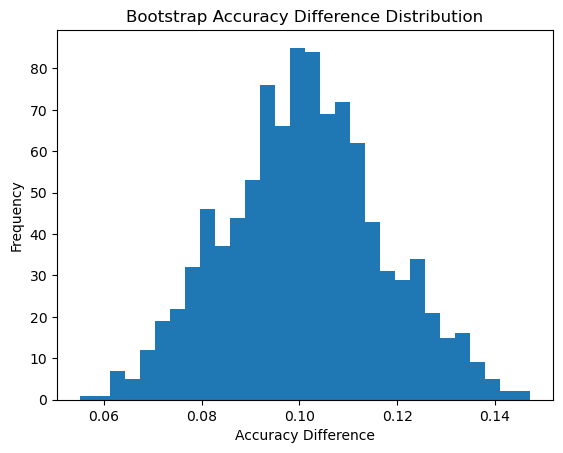

In [51]:
import matplotlib.pyplot as plt

plt.hist(diffs, bins=30)
plt.title("Bootstrap Accuracy Difference Distribution")
plt.xlabel("Accuracy Difference")
plt.ylabel("Frequency")
plt.savefig("accuracy_difference.png",dpi=1200)
plt.show()

In [52]:
print(np.std(diffs))

0.01619091934805619
